# CS 6220 Homework 4
**Name:** Rutuja Jadhav

## Part 1: Frequent Itemsets

### transactions, support, confidence

In [29]:
from itertools import combinations

transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter", "Eggs"],
    ["Milk", "Cereal"],
    ["Bread", "Eggs"],
    ["Milk", "Cereal", "Yogurt"],
    ["Diapers", "Beer"],
    ["Diapers", "Beer", "Chips"],
    ["Apples", "Bananas"],
    ["Apples", "Bananas", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Cereal", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Apples", "Milk"],
    ["Diapers", "Beer", "Bread", "Eggs"],
    ["Yogurt", "Cereal"],
    ["Bread", "Butter", "Bananas", "Milk"],
    ["Milk", "Eggs"],
    ["Apples", "Bananas", "Yogurt"],
    ["Bread", "Butter", "Cereal", "Milk"],
    ["Chips", "Salsa"]
]

def support(candidate_itemset, list_of_transactions):
    candidate_itemset = set(candidate_itemset)
    count = sum(1 for t in list_of_transactions if candidate_itemset.issubset(set(t)))
    return count / len(list_of_transactions)

def confidence(antecedent, consequent, list_of_transactions):
    rule_itemset = set(antecedent) | set(consequent)
    return support(rule_itemset, list_of_transactions) / support(antecedent, list_of_transactions)

def lift(antecedent, consequent, list_of_transactions):
    sup_a = support(antecedent, list_of_transactions)
    sup_c = support(consequent, list_of_transactions)
    sup_ac = support(set(antecedent) | set(consequent), list_of_transactions)
    return sup_ac / (sup_a * sup_c)

print(support(["Bread","Milk"], transactions))
print(confidence(["Bread"], ["Milk"], transactions))

0.25
0.625


### apriori: join, prune, count

In [30]:
def join_step(freq_itemsets_k_minus_1):
    # join (k-1)-itemsets that share the first k-2 items
    candidates = set()
    itemsets_sorted = [tuple(sorted(s)) for s in freq_itemsets_k_minus_1]
    n = len(itemsets_sorted)
    for i in range(n):
        for j in range(i+1, n):
            a, b = itemsets_sorted[i], itemsets_sorted[j]
            if a[:-1] == b[:-1]:
                new_candidate = tuple(sorted(set(a) | set(b)))
                if len(new_candidate) == len(a) + 1:
                    candidates.add(new_candidate)
    return candidates

def prune_step(candidates, freq_itemsets_k_minus_1_set):
    # drop a candidate if any of its (k-1)-subsets isn't frequent
    survivors, pruned = [], []
    for cand in candidates:
        subsets = combinations(cand, len(cand) - 1)
        if all(frozenset(sub) in freq_itemsets_k_minus_1_set for sub in subsets):
            survivors.append(cand)
        else:
            pruned.append(cand)
    return survivors, pruned

def apriori(transactions, min_sup):
    items = sorted(set(item for t in transactions for item in t))
    L = {}
    pruned_counts = {}

    L1 = [((item,), s) for item in items if (s := support([item], transactions)) >= min_sup]
    L[1] = L1

    k = 2
    while L[k-1]:
        freq_prev = [frozenset(it) for it, s in L[k-1]]
        candidates = join_step(freq_prev)
        survivors, pruned = prune_step(candidates, set(freq_prev))
        pruned_counts[k] = len(pruned)

        Lk = [(cand, s) for cand in survivors if (s := support(cand, transactions)) >= min_sup]
        L[k] = Lk
        k += 1

    del L[k-1]
    return L, pruned_counts

### Q3: frequent itemsets at min_sup=0.25

In [31]:
L, pruned = apriori(transactions, min_sup=0.25)
for k in sorted(L.keys()):
    print(f"--- k={k} ---  (pruned at this k: {pruned.get(k, 0)})")
    for itemset, sup in L[k]:
        print(f"  {itemset}: support={sup:.3f}")

--- k=1 ---  (pruned at this k: 0)
  ('Bread',): support=0.400
  ('Butter',): support=0.300
  ('Cereal',): support=0.250
  ('Eggs',): support=0.300
  ('Milk',): support=0.550
--- k=2 ---  (pruned at this k: 0)
  ('Bread', 'Eggs'): support=0.250
  ('Butter', 'Milk'): support=0.250
  ('Bread', 'Milk'): support=0.250
  ('Bread', 'Butter'): support=0.300
--- k=3 ---  (pruned at this k: 2)
  ('Bread', 'Butter', 'Milk'): support=0.250


pruning only really kicks in at k=3 (2 candidates pruned there, 0 everywhere else) -- not a lot of pruning overall since this dataset is small, but it still saved 2 unnecessary support counts.

### Q4: {Butter, Bread, Eggs}

In [32]:
for item in ['Butter','Bread','Eggs']:
    print(item, support([item], transactions))
for pair in [('Butter','Bread'), ('Butter','Eggs'), ('Bread','Eggs')]:
    print(pair, support(pair, transactions))
print(('Butter','Bread','Eggs'), support(('Butter','Bread','Eggs'), transactions))

Butter 0.3
Bread 0.4
Eggs 0.3
('Butter', 'Bread') 0.3
('Butter', 'Eggs') 0.15
('Bread', 'Eggs') 0.25
('Butter', 'Bread', 'Eggs') 0.15


it would be generated as a candidate (joins from {Bread,Butter} and {Bread,Eggs}, which share the 'Bread' prefix), but gets pruned right away since {Butter,Eggs}=0.15 isn't frequent.

### apriori_rules

In [33]:
def apriori_rules(frequent_itemsets, transactions, min_conf):
    all_rules = []
    for itemset in frequent_itemsets:
        itemset = tuple(sorted(itemset))
        m = len(itemset)
        if m < 2:
            continue
        itemset_set = set(itemset)

        # H1: all 1-item consequents that meet min_conf
        H1 = []
        for item in itemset:
            consequent = (item,)
            antecedent = tuple(sorted(itemset_set - {item}))
            conf = confidence(antecedent, consequent, transactions)
            if conf >= min_conf:
                H1.append(consequent)
                all_rules.append({'antecedent': antecedent, 'consequent': consequent,
                                   'support': support(itemset, transactions), 'confidence': conf,
                                   'lift': lift(antecedent, consequent, transactions)})

        H_prev = H1
        size = 1
        while H_prev and size + 1 < m:
            candidates = join_step([frozenset(h) for h in H_prev])
            candidates = [c for c in candidates if set(c).issubset(itemset_set)]
            survivors, _ = prune_step(candidates, set(frozenset(h) for h in H_prev))

            H_next = []
            for consequent in survivors:
                antecedent = tuple(sorted(itemset_set - set(consequent)))
                if not antecedent:
                    continue
                conf = confidence(antecedent, consequent, transactions)
                if conf >= min_conf:
                    H_next.append(consequent)
                    all_rules.append({'antecedent': antecedent, 'consequent': consequent,
                                       'support': support(itemset, transactions), 'confidence': conf,
                                       'lift': lift(antecedent, consequent, transactions)})
            H_prev = H_next
            size += 1
    return all_rules

### Q5: association rules at min_conf=0.6

In [34]:
all_itemsets = [it for k in L for it, s in L[k] if len(it) >= 2]
rules = apriori_rules(all_itemsets, transactions, min_conf=0.6)
for r in rules:
    print(f"{r['antecedent']} -> {r['consequent']}  sup={r['support']:.3f}  conf={r['confidence']:.3f}  lift={r['lift']:.3f}")

('Eggs',) -> ('Bread',)  sup=0.250  conf=0.833  lift=2.083
('Bread',) -> ('Eggs',)  sup=0.250  conf=0.625  lift=2.083
('Butter',) -> ('Milk',)  sup=0.250  conf=0.833  lift=1.515
('Bread',) -> ('Milk',)  sup=0.250  conf=0.625  lift=1.136
('Butter',) -> ('Bread',)  sup=0.300  conf=1.000  lift=2.500
('Bread',) -> ('Butter',)  sup=0.300  conf=0.750  lift=2.500
('Butter', 'Milk') -> ('Bread',)  sup=0.250  conf=1.000  lift=2.500
('Bread', 'Milk') -> ('Butter',)  sup=0.250  conf=1.000  lift=3.333
('Bread', 'Butter') -> ('Milk',)  sup=0.250  conf=0.833  lift=1.515
('Butter',) -> ('Bread', 'Milk')  sup=0.250  conf=0.833  lift=3.333
('Bread',) -> ('Butter', 'Milk')  sup=0.250  conf=0.625  lift=2.500


Q6: lift below 1 means the two items actually happen together less than you'd expect if they were independent -- the antecedent makes the consequent less likely, not more.

Q7: strongest is (Bread, Milk) -> Butter -- perfect confidence (1.0) and the highest lift (3.333), with reasonable support (0.25). weakest is Bread -> Milk -- lowest lift (1.136, barely above independent) and the lowest confidence (0.625) of the bunch, so it's barely more than coincidence.

## Part 3: Hierarchical Clustering

### Q9: the dataset

(370, 2)


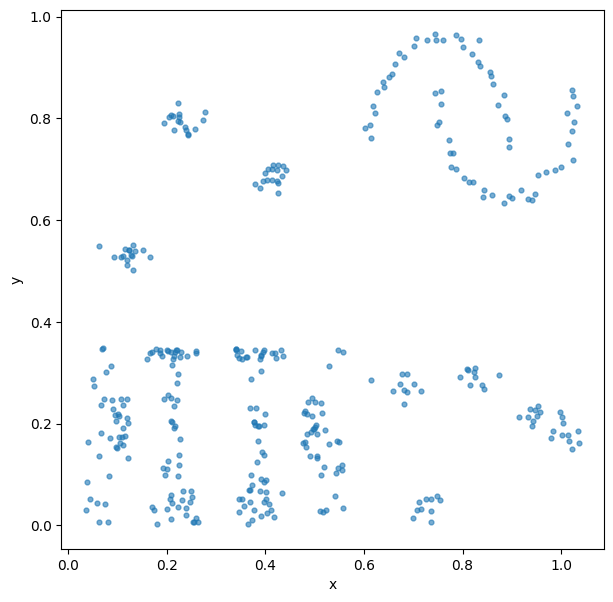

In [35]:
import numpy as np
import matplotlib.pyplot as plt
data = np.loadtxt('/content/clustering.txt', delimiter=',')
print(data.shape)

plt.figure(figsize=(7,7))
plt.scatter(data[:,0], data[:,1], s=12, alpha=0.6)
plt.xlabel('x'); plt.ylabel('y')
plt.show()

by eye I'd say about 12-13 natural clusters -- a bunch of tight blobs plus what looks like two crescent/spiral arcs in the top right.

### HAC with incremental distance updates

In [36]:
def euclidean(p1, p2):
    return np.sqrt(np.sum((p1 - p2) ** 2))

class HAC:
    def __init__(self, distance_mode='min_dist'):
        self.distance_mode = distance_mode

    def fit(self, X):
        n = X.shape[0]
        self.n = n

        # raw point distances -- the ONLY place we touch the actual points
        dist = {}
        for i in range(n):
            for j in range(i + 1, n):
                dist[(i, j)] = euclidean(X[i], X[j])

        def get_dist(a, b):
            key = (a, b) if a < b else (b, a)
            return dist[key]

        def set_dist(a, b, d):
            key = (a, b) if a < b else (b, a)
            dist[key] = d

        active = set(range(n))
        size = {i: 1 for i in range(n)}
        merges = []
        next_id = n

        while len(active) > 1:
            # find the closest pair of active clusters
            best, best_d = None, None
            active_list = list(active)
            for ii in range(len(active_list)):
                for jj in range(ii + 1, len(active_list)):
                    a, b = active_list[ii], active_list[jj]
                    d = get_dist(a, b)
                    if best_d is None or d < best_d:
                        best_d, best = d, (a, b)
            a, b = best
            merges.append((a, b, best_d, next_id))

            # incremental update: new cluster's distance to every other active
            # cluster k, computed only from d(a,k) and d(b,k) -- no raw points involved
            for k in active:
                if k == a or k == b:
                    continue
                d_ak, d_bk = get_dist(a, k), get_dist(b, k)
                new_d = min(d_ak, d_bk) if self.distance_mode == 'min_dist' else max(d_ak, d_bk)
                set_dist(next_id, k, new_d)

            size[next_id] = size[a] + size[b]
            active.discard(a); active.discard(b); active.add(next_id)
            next_id += 1

        self.merges = merges
        return self

    def linkage_matrix(self):
        # scipy-compatible format, for dendrogram plotting only
        Z = []
        size = {i: 1 for i in range(self.n)}
        for a, b, d, new_id in self.merges:
            Z.append([a, b, d, size[a] + size[b]])
            size[new_id] = size[a] + size[b]
        return np.array(Z)

    def cluster_membership(self, n_clusters):
        # merges happen in increasing-distance order, so stopping early after
        # (n - n_clusters) merges leaves exactly n_clusters groups
        parent = {i: i for i in range(self.n)}
        def find(x):
            while parent[x] != x:
                x = parent[x]
            return x

        for a, b, d, new_id in self.merges[:self.n - n_clusters]:
            ra, rb = find(a), find(b)
            parent[ra] = new_id; parent[rb] = new_id; parent[new_id] = new_id

        roots = [find(i) for i in range(self.n)]
        unique_roots = sorted(set(roots))
        root_to_label = {r: i for i, r in enumerate(unique_roots)}
        return np.array([root_to_label[r] for r in roots])

### Q10: min_dist

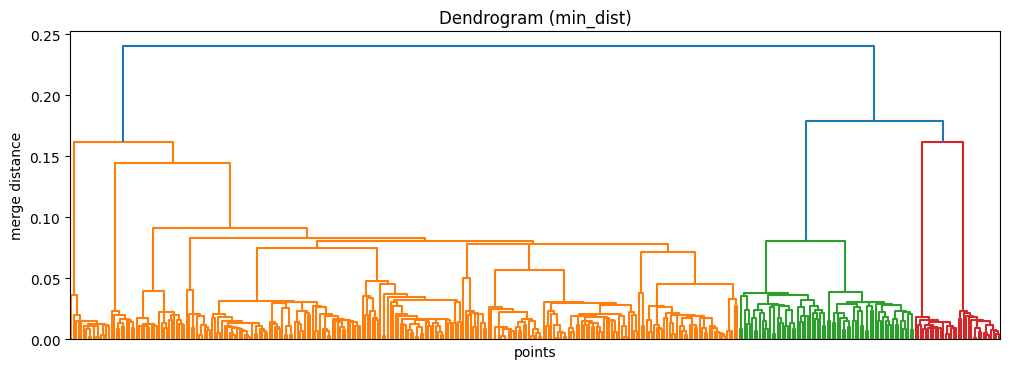

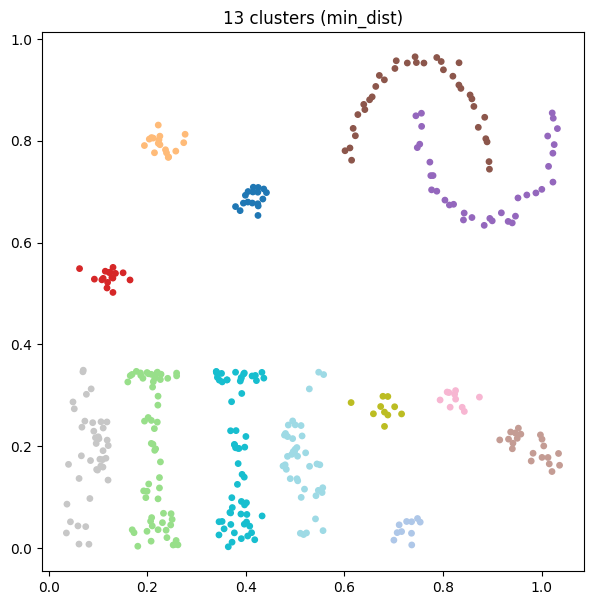

In [37]:
from scipy.cluster.hierarchy import dendrogram

hac_min = HAC(distance_mode='min_dist').fit(data)
Z_min = hac_min.linkage_matrix()

plt.figure(figsize=(12,4))
dendrogram(Z_min, no_labels=True)
plt.title('Dendrogram (min_dist)')
plt.xlabel('points'); plt.ylabel('merge distance')
plt.show()

labels_min = hac_min.cluster_membership(13)
plt.figure(figsize=(7,7))
plt.scatter(data[:,0], data[:,1], c=labels_min, cmap='tab20', s=15)
plt.title('13 clusters (min_dist)')
plt.show()

min_dist nails the two spiral arcs as single clusters -- matches my intuition really well.

### Q11: max_dist

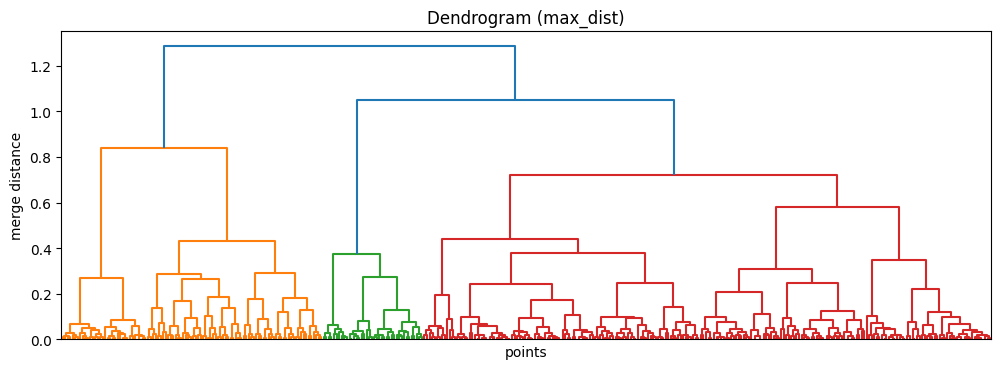

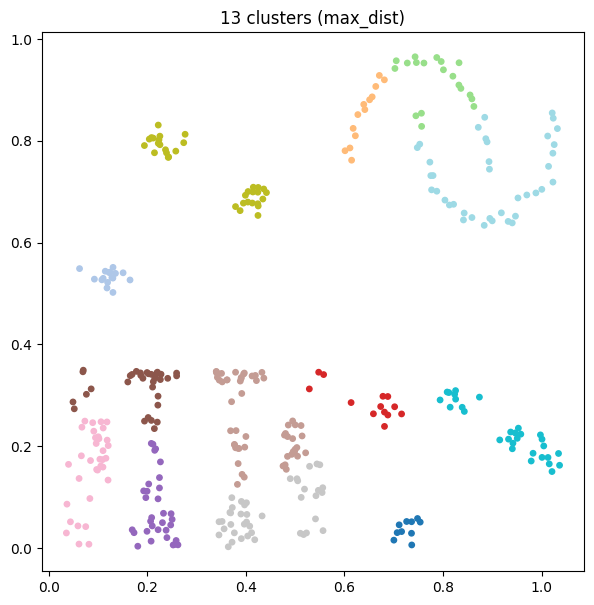

In [38]:
hac_max = HAC(distance_mode='max_dist').fit(data)
Z_max = hac_max.linkage_matrix()

plt.figure(figsize=(12,4))
dendrogram(Z_max, no_labels=True)
plt.title('Dendrogram (max_dist)')
plt.xlabel('points'); plt.ylabel('merge distance')
plt.show()

labels_max = hac_max.cluster_membership(13)
plt.figure(figsize=(7,7))
plt.scatter(data[:,0], data[:,1], c=labels_max, cmap='tab20', s=15)
plt.title('13 clusters (max_dist)')
plt.show()

max_dist chops both spiral arcs into several pieces instead of keeping them whole -- doesn't match intuition nearly as well here.

Q12: min_dist matches my intuition more. single-link only cares about the closest pair of points between two clusters, so it can 'chain' along a curved shape and keep an entire arc together. complete-link cares about the farthest pair, so an elongated or curved cluster gets penalized hard (two points at opposite ends of the arc look very far apart), and it ends up chopping the arc into smaller, more compact-looking pieces instead.